# Sports Prediction — Complete Image Classification Project

**Model:** Existing Teachable Machine Keras model (`keras_model.h5`)  
**Dataset:** `test` folder containing one subfolder per sport and 5 images per folder  
**Outputs:** single-image prediction, probability table for every sport, all-image predictions, accuracy, classification report, confusion matrix, and CSV exports.

> Update `BASE_DIR` if your project folder is somewhere else. Keep `class_names` in the exact order used when the model was trained.

## 1. Install dependencies
Run this cell only if packages are missing. Restart the kernel if you install packages.

In [46]:
%pip install pandas numpy pillow matplotlib seaborn scikit-learn tf-keras

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Import libraries

In [47]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from IPython.display import display
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import tensorflow as tf
import tf_keras

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 3. Set project paths and class labels

In [48]:
MODEL_PATH = r"D:\DL\PR4\PR4\keras_model.h5"
SAMPLE_IMAGE = r"D:\DL\PR4\test\sample.jpg"
TEST_FOLDER = r"D:\DL\PR4\test"
OUTPUT_FOLDER = r"D:\DL\PR4\output"

os.makedirs(OUTPUT_FOLDER, exist_ok=True)
class_names = [
    "air hockey",
    "archery",
    "baseball",
    "basketball",
    "bowling",
    "boxing",
    "bull riding",
    "cricket",
    "football",
    "golf",
    "hockey",
    "horse racing",
    "tug of war"
]

print("Model exists:", os.path.exists(MODEL_PATH), MODEL_PATH)
print("Test folder exists:", os.path.exists(TEST_FOLDER), TEST_FOLDER)
print("Output folder:", OUTPUT_FOLDER)

Model exists: True D:\DL\PR4\PR4\keras_model.h5
Test folder exists: True D:\DL\PR4\test
Output folder: D:\DL\PR4\output


## 4. Load the trained model

In [49]:
model = tf_keras.models.load_model(MODEL_PATH, compile=False)
model.summary()

Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 sequential_1 (Sequential)   (None, 1280)              410208    
                                                                 
 sequential_3 (Sequential)   (None, 13)                129400    
                                                                 
Total params: 539608 (2.06 MB)
Trainable params: 525528 (2.00 MB)
Non-trainable params: 14080 (55.00 KB)
_________________________________________________________________


## 5. Image preprocessing and prediction functions

In [50]:
IMAGE_SIZE = (224, 224)

def preprocess_image(image_path):
    image = Image.open(image_path).convert("RGB")
    image = image.resize(IMAGE_SIZE)
    image_array = np.asarray(image, dtype=np.float32)
    image_array = (image_array / 127.5) - 1.0
    return np.expand_dims(image_array, axis=0)

def predict_image(image_path):
    image_array = preprocess_image(image_path)
    raw_prediction = model.predict(image_array, verbose=0)[0]

    if len(raw_prediction) != len(class_names):
        raise ValueError(
            f"Model outputs {len(raw_prediction)} classes, "
            f"but class_names has {len(class_names)} labels. "
            "Check the model's exact training labels and order."
        )

    predicted_index = int(np.argmax(raw_prediction))
    probabilities = raw_prediction * 100

    return {
        "predicted_sport": class_names[predicted_index],
        "confidence": float(probabilities[predicted_index]),
        "probabilities": probabilities
    }

## 6. Predict one sample image

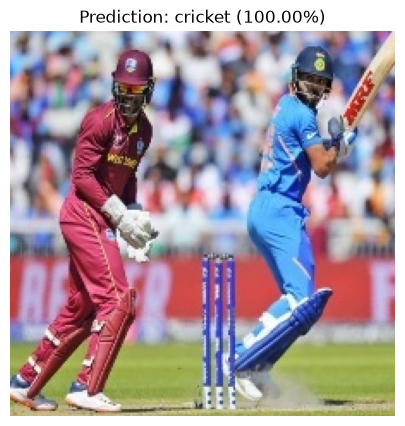

Predicted sport: cricket
Confidence: 100.00%


In [51]:
SAMPLE_IMAGE = r"D:\DL\PR4\test\sample.jpg"
if os.path.exists(SAMPLE_IMAGE):

    result = predict_image(SAMPLE_IMAGE)

    plt.figure(figsize=(5, 5))
    plt.imshow(Image.open(SAMPLE_IMAGE).convert("RGB"))
    plt.axis("off")
    plt.title(f"Prediction: {result['predicted_sport']} ({result['confidence']:.2f}%)")
    plt.show()

    print("Predicted sport:", result["predicted_sport"])
    print(f"Confidence: {result['confidence']:.2f}%")
else:
    print("sample.jpg not found. Choose an image path in the next section.")

## 7. Display probability table for all sports

,Sport,Probability (%)
0,cricket,100.0
1,archery,0.0
2,baseball,0.0
3,basketball,0.0
4,air hockey,0.0
5,bowling,0.0
6,boxing,0.0
7,bull riding,0.0
8,football,0.0
9,golf,0.0


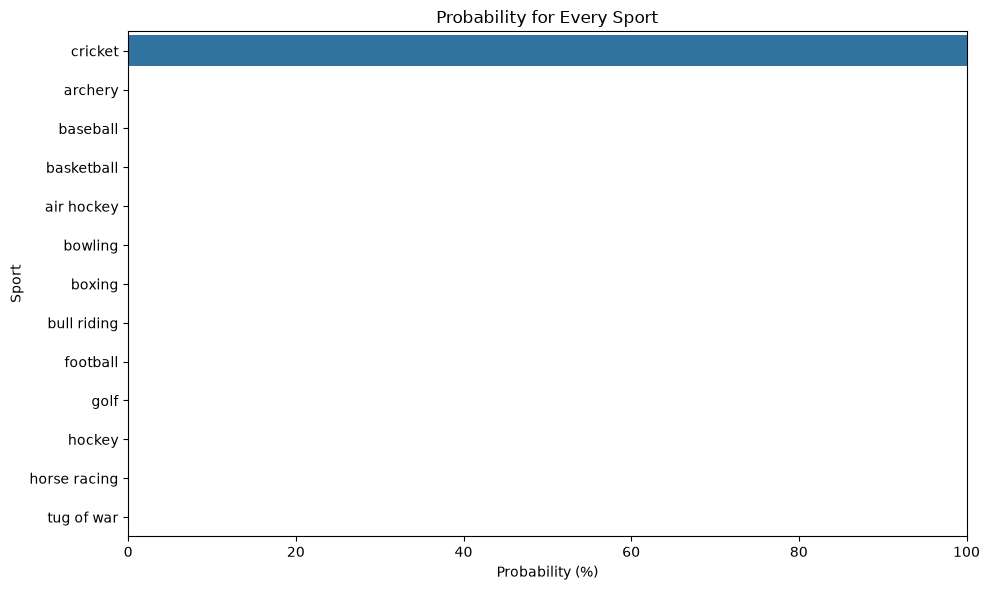

In [52]:
# Uses sample.jpg if it exists. Otherwise change IMAGE_PATH to any image.
IMAGE_PATH = SAMPLE_IMAGE

if os.path.exists(IMAGE_PATH):
    result = predict_image(IMAGE_PATH)
    probability_df = pd.DataFrame({
        "Sport": class_names,
        "Probability (%)": np.round(result["probabilities"], 2)
    }).sort_values("Probability (%)", ascending=False).reset_index(drop=True)

    display(probability_df)

    plt.figure(figsize=(10, 6))
    sns.barplot(data=probability_df, x="Probability (%)", y="Sport")
    plt.title("Probability for Every Sport")
    plt.xlim(0, 100)
    plt.tight_layout()
    plt.show()
else:
    print("Set IMAGE_PATH to an existing image before running this cell.")

## 8. Predict all images in every sport folder

In [53]:
valid_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
results = []

for actual_sport in os.listdir(TEST_FOLDER):
    sport_folder = os.path.join(TEST_FOLDER, actual_sport)

    if not os.path.isdir(sport_folder):
        continue

    for image_name in os.listdir(sport_folder):
        if image_name.lower().endswith(valid_extensions):
            image_path = os.path.join(sport_folder, image_name)
            result = predict_image(image_path)

            row = {
                "Actual Sport": actual_sport,
                "Image": image_name,
                "Image Path": image_path,
                "Predicted Sport": result["predicted_sport"],
                "Confidence (%)": round(result["confidence"], 2),
                "Correct": result["predicted_sport"].strip().lower()
                           == actual_sport.strip().lower()
            }

            for i, sport in enumerate(class_names):
                row[f"{sport} (%)"] = round(float(result["probabilities"][i]), 2)

            results.append(row)

results_df = pd.DataFrame(results)

if results_df.empty:
    print("No images found. Check TEST_FOLDER and the folder structure.")
else:
    display(results_df[["Actual Sport", "Image", "Predicted Sport", "Confidence (%)", "Correct"]])
    print("Total images:", len(results_df))

,Actual Sport,Image,Predicted Sport,Confidence (%),Correct
0,air hockey,1.jpg,air hockey,100.00,True
1,air hockey,2.jpg,air hockey,99.82,True
2,air hockey,3.jpg,air hockey,100.00,True
3,air hockey,4.jpg,air hockey,100.00,True
4,air hockey,5.jpg,air hockey,99.95,True
...,...,...,...,...,...
60,tug of war,1.jpg,tug of war,76.17,True
61,tug of war,2.jpg,tug of war,100.00,True
62,tug of war,3.jpg,tug of war,99.42,True
63,tug of war,4.jpg,tug of war,99.97,True


Total images: 65


## 9. Evaluate overall accuracy

In [54]:
if not results_df.empty:
    accuracy = accuracy_score(results_df["Actual Sport"].str.lower(),
                              results_df["Predicted Sport"].str.lower()) * 100

    print("Total Images:", len(results_df))
    print("Correct Predictions:", int(results_df["Correct"].sum()))
    print("Incorrect Predictions:", int((~results_df["Correct"]).sum()))
    print(f"Accuracy: {accuracy:.2f}%")

Total Images: 65
Correct Predictions: 65
Incorrect Predictions: 0
Accuracy: 100.00%


## 10. Classification report

In [55]:
if not results_df.empty:
    actual_labels = results_df["Actual Sport"].str.lower()
    predicted_labels = results_df["Predicted Sport"].str.lower()
    labels = [name.lower() for name in class_names]

    print(classification_report(
        actual_labels,
        predicted_labels,
        labels=labels,
        target_names=class_names,
        zero_division=0
    ))

              precision    recall  f1-score   support

  air hockey       1.00      1.00      1.00         5
     archery       1.00      1.00      1.00         5
    baseball       1.00      1.00      1.00         5
  basketball       1.00      1.00      1.00         5
     bowling       1.00      1.00      1.00         5
      boxing       1.00      1.00      1.00         5
 bull riding       1.00      1.00      1.00         5
     cricket       1.00      1.00      1.00         5
    football       1.00      1.00      1.00         5
        golf       1.00      1.00      1.00         5
      hockey       1.00      1.00      1.00         5
horse racing       1.00      1.00      1.00         5
  tug of war       1.00      1.00      1.00         5

    accuracy                           1.00        65
   macro avg       1.00      1.00      1.00        65
weighted avg       1.00      1.00      1.00        65



## 11. Confusion matrix

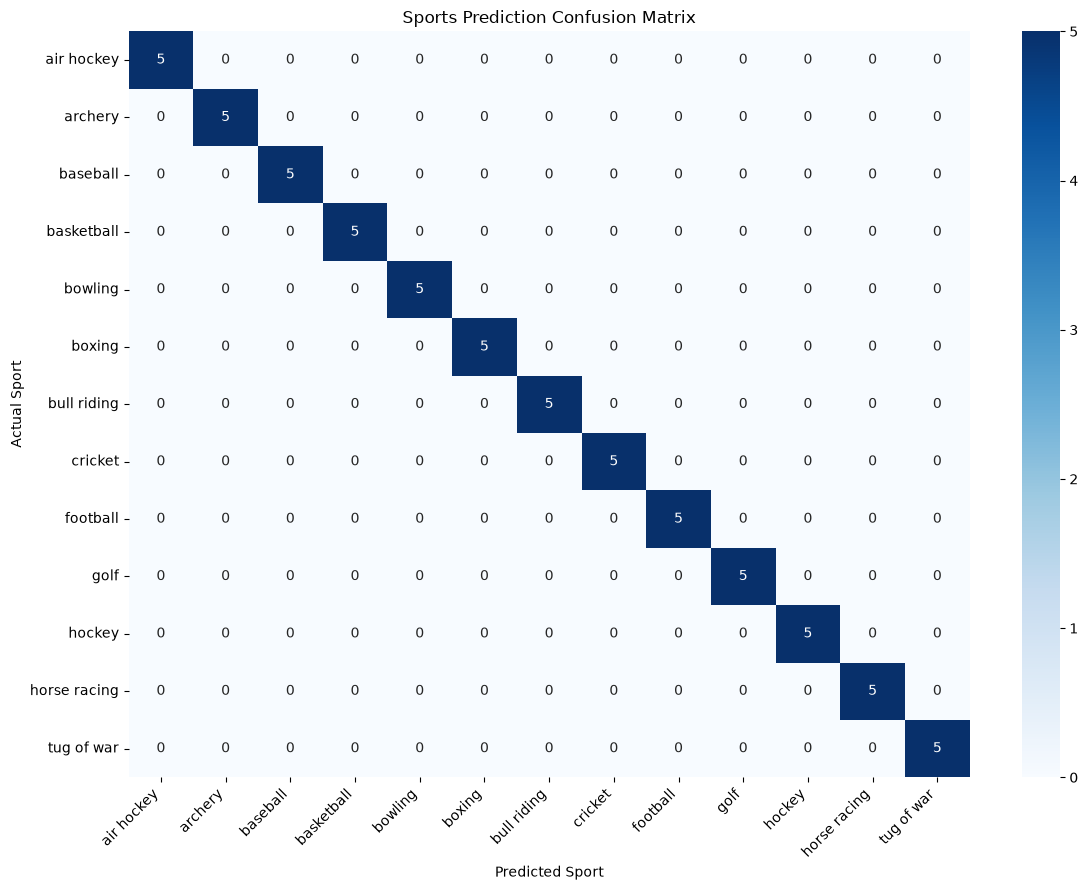

In [56]:
if not results_df.empty:
    actual_labels = results_df["Actual Sport"].str.lower()
    predicted_labels = results_df["Predicted Sport"].str.lower()
    labels = [name.lower() for name in class_names]

    cm = confusion_matrix(actual_labels, predicted_labels, labels=labels)

    plt.figure(figsize=(12, 9))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted Sport")
    plt.ylabel("Actual Sport")
    plt.title("Sports Prediction Confusion Matrix")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

## 12. Save all predictions and probability columns to CSV

In [57]:
if not results_df.empty:
    predictions_path = os.path.join(OUTPUT_FOLDER, "sports_predictions.csv")
    results_df.to_csv(predictions_path, index=False)
    print("Saved:", predictions_path)

Saved: D:\DL\PR4\output\sports_predictions.csv


## 13. Show correct and incorrect predictions

In [58]:
if not results_df.empty:
    print("Correct predictions")
    display(results_df.loc[results_df["Correct"],
                           ["Actual Sport", "Image", "Predicted Sport", "Confidence (%)"]])

    print("Incorrect predictions")
    display(results_df.loc[~results_df["Correct"],
                           ["Actual Sport", "Image", "Predicted Sport", "Confidence (%)"]])

Correct predictions


,Actual Sport,Image,Predicted Sport,Confidence (%)
0,air hockey,1.jpg,air hockey,100.00
1,air hockey,2.jpg,air hockey,99.82
2,air hockey,3.jpg,air hockey,100.00
3,air hockey,4.jpg,air hockey,100.00
4,air hockey,5.jpg,air hockey,99.95
...,...,...,...,...
60,tug of war,1.jpg,tug of war,76.17
61,tug of war,2.jpg,tug of war,100.00
62,tug of war,3.jpg,tug of war,99.42
63,tug of war,4.jpg,tug of war,99.97


Incorrect predictions


,Actual Sport,Image,Predicted Sport,Confidence (%)


## 14. Predict any new image

In [59]:
# Change this to the path of any new image you want to classify.
NEW_IMAGE_PATH = r"D:\DL\PR4\test\cricket\1.jpg"

if os.path.exists(NEW_IMAGE_PATH):
    result = predict_image(NEW_IMAGE_PATH)

    print("Predicted sport:", result["predicted_sport"])
    print(f"Confidence: {result['confidence']:.2f}%")

    new_probabilities = pd.DataFrame({
        "Sport": class_names,
        "Probability (%)": np.round(result["probabilities"], 2)
    }).sort_values("Probability (%)", ascending=False).reset_index(drop=True)

    display(new_probabilities)
else:
    print("Image not found. Update NEW_IMAGE_PATH.")

Predicted sport: cricket
Confidence: 100.00%


,Sport,Probability (%)
0,cricket,100.0
1,archery,0.0
2,baseball,0.0
3,basketball,0.0
4,air hockey,0.0
5,bowling,0.0
6,boxing,0.0
7,bull riding,0.0
8,football,0.0
9,golf,0.0
